In [7]:
''' getting important libraries which is used during our Model building
    from sklearn.linear_model we imported Linear Regression,
    and then we evaluted our model using various metrics from sklearn.metrics like
    r2_score,mean_absolute_error,mean_squared_Error'''
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

In [8]:
'''making a DF pipeline to our cleaned data set
   known as 'delhivery_cleaned_with_chokes.csv' 
   then we checked for any null present'''
df = pd.read_csv('delhivery_cleaned_with_chokes.csv')
df.isnull().sum()

C:\Users\NISHANT SHARMA\AppData\Local\Temp\ipykernel_21772\2254640942.py:4: DtypeWarning: Columns (27) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('delhivery_cleaned_with_chokes.csv')


data                                   0
trip_creation_time                     0
route_schedule_uuid                    0
route_type                             0
trip_uuid                              0
source_center                          0
source_name                            0
destination_center                     0
destination_name                       0
od_start_time                          0
od_end_time                            0
start_scan_to_end_scan                 0
is_cutoff                              0
cutoff_factor                          0
cutoff_timestamp                       0
actual_distance_to_destination         0
actual_time                            0
osrm_time                              0
osrm_distance                          0
factor                                 0
segment_actual_time                    0
segment_osrm_time                      0
segment_osrm_distance                  0
segment_factor                         0
log_segment_fact

In [9]:
''' since our column log_segment_factor ,log_segment_actual_time
    has 9,18 null respective thats why we tried to check if 
    'segment_actual_time' and  'segment_factor'''
# Check for zeros or negative values
print("Negative or zero values in segment_actual_time:", (df['segment_actual_time'] < 0).sum())
print("Negative or zero values in segment_factor:", (df['segment_factor'] < 0).sum())

# Check if there are already null values in the original columns
print("Existing nulls in segment_actual_time:", df['segment_actual_time'].isnull().sum())


Negative or zero values in segment_actual_time: 21
Negative or zero values in segment_factor: 2365
Existing nulls in segment_actual_time: 0


In [10]:
''' since both of then has Negative value this could we due to 
    system glitch in recording time actual time and osrm time
    thus we are creating a cleaned DataFrame on the logic
    that it contain only those data which has 
    df['segment_actual_time']>=0 and df['segment_factor'] >=0 
    we then created a shallow copy of them 
    after finally our data is containing non negative values thus we 
    applied log1p which can handle values >= 0
    thus we calculated them for 'log_segment_actual_time','log_segment_factor'
    and then we again saved this new cleaned file as 'delhivery_cleaned_1.csv' and index=False
    for not creating new column with  0,1,2....'''
df_cleaned = df[(df['segment_actual_time']>=0) & (df['segment_factor'] >=0)].copy()
df_cleaned['log_segment_actual_time'] = np.log1p(df_cleaned['segment_actual_time'])
df_cleaned['log_segment_factor'] = np.log1p(df_cleaned['segment_factor'])
df_cleaned.to_csv('delhivery_cleaned_1.csv',index=False)

In [11]:
#now we accessing the delhivery_cleaned_1 dataset and checking its columns.
df=pd.read_csv('delhivery_cleaned_1.csv')
df.columns

Index(['data', 'trip_creation_time', 'route_schedule_uuid', 'route_type',
       'trip_uuid', 'source_center', 'source_name', 'destination_center',
       'destination_name', 'od_start_time', 'od_end_time',
       'start_scan_to_end_scan', 'is_cutoff', 'cutoff_factor',
       'cutoff_timestamp', 'actual_distance_to_destination', 'actual_time',
       'osrm_time', 'osrm_distance', 'factor', 'segment_actual_time',
       'segment_osrm_time', 'segment_osrm_distance', 'segment_factor',
       'log_segment_factor', 'log_segment_osrm_distance',
       'log_segment_osrm_time', 'log_segment_actual_time', 'log_factor',
       'chokepoint_flag', 'segment_name', 'log_actual_time',
       'log_start_scan_to_end_scan', 'log_cutoff_factor',
       'log_actual_distance_to_destination'],
      dtype='object')

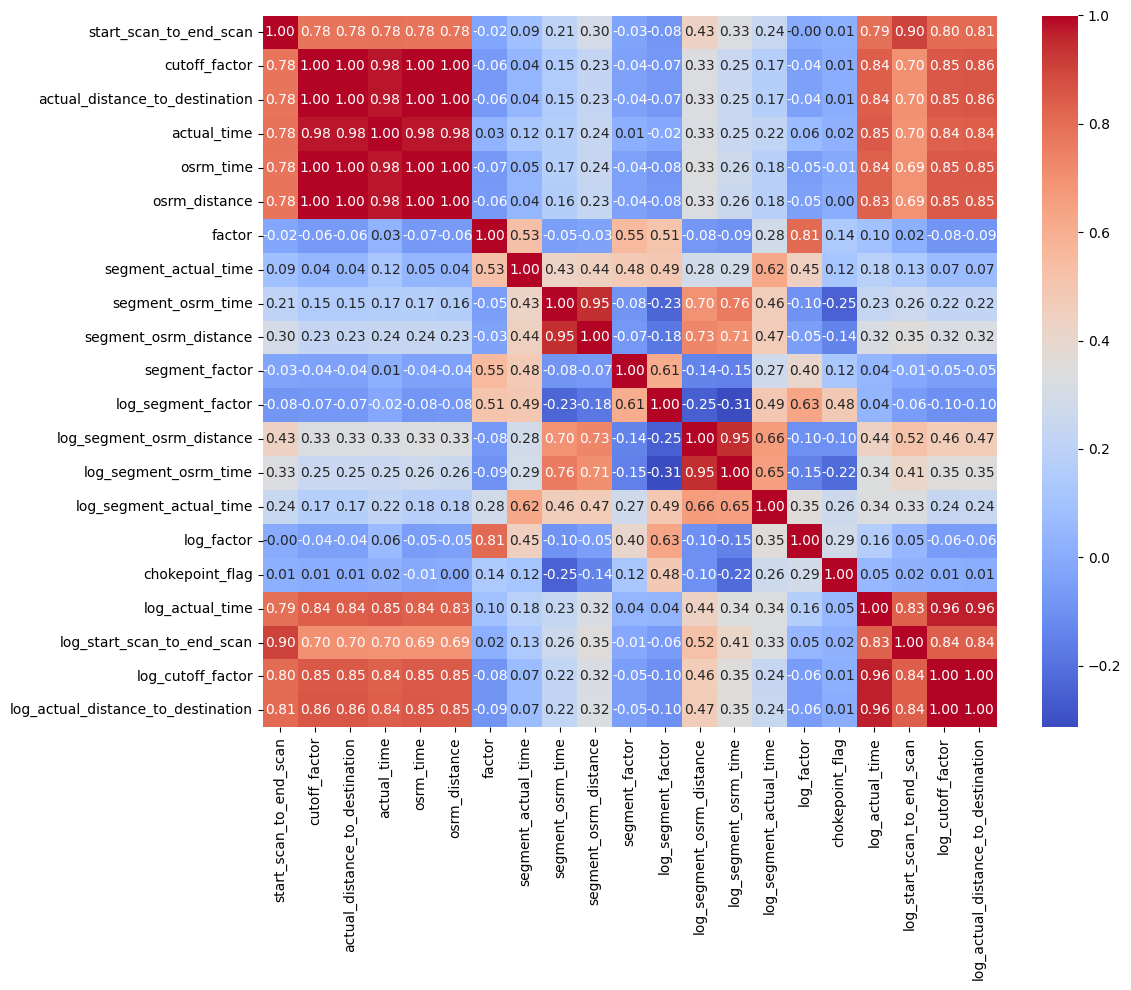

In [12]:
''' We created a new data Frame which has only Numeric values
    since we are creating a correlation table for that we thus calculated
    numeric_corr table for correlation and after that we made a figure with figsize =(12,10)
    and then we created an heatmao of correlation we annotation (to present values) and colormap='coolwarm'
    '''
numeric_df = df.select_dtypes(include=['number'])
numeric_corr = numeric_df.corr()
plt.figure(figsize=(12,10))
sns.heatmap(numeric_corr,annot=True,cmap='coolwarm',fmt='.2f')
plt.tight_layout()
plt.show()

In [13]:
''' in selected columns we had only those columns which has high correlation
    with our target columns 'log_segment_actual_time' 
    since our data is already divided into 'training' and 'test'  we creating
    train_df and test_df base on the logic that column df['data'] == 'training'
    data frame column == training for train_df and test_df=='test'
    similiarly  we getting out X_test and y_test , X_train and Y_train 
    X_train,X_test is selected using selected_features 
'''
selected_features = ['log_segment_osrm_distance','log_segment_osrm_time','log_cutoff_factor','log_actual_distance_to_destination']
target_col = 'log_segment_actual_time'
train_df = df[df['data'] == 'training']
test_df = df[df['data'] == 'test']
X_train = train_df[selected_features]
y_train = train_df['log_segment_actual_time']
X_test  = test_df[selected_features]
y_test = test_df['log_segment_actual_time']
''' Since train test split is done then
    now we building our model .
    we have used LinearRegression.
    because it is the most baseline and basic model which can be possibly made without
    doing any extra hustle for 
    and mainly because ETA prediction is fundamentally a regression problem because the 
    target variable—delivery time—is continuous (measured in minutes, hours, or days) rather
    than categorical. Linear regression models this by establishing a direct relationship between the 
    continuous outcome and independent factors like distance, traffic indices, or processing bottlenecks
'''
model = LinearRegression()
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
''' we thus then predicted our ETA using first by fitting our 
    training data then by predicting
    model.predict(X_test) 
    we then converted y_test from log transform 
    to actual_time/orignal time then predicted
'''
y_test_org = np.expm1(y_test)
y_pred_org = np.expm1(y_pred)
''' we then check our goodness of fit using various metrices like
    mean_absolute_error,mean_squared_error,root_mean_squared_error,
    r2_score and printing them.
'''
mae = mean_absolute_error(y_test_org,y_pred_org)
mse = mean_squared_error(y_test_org,y_pred_org)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_org,y_pred_org)
print("--- Model Performance on Pre-Split Test Data ---")
print(f"R² Score (Variance Explained): {r2:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")


--- Model Performance on Pre-Split Test Data ---
R² Score (Variance Explained): 0.1154
Mean Absolute Error (MAE): 14.6936
Root Mean Squared Error (RMSE): 52.8418


In [14]:
''' we thus calculated our trip level performnace
    we first created a evaluting DataFrame 
    and then a trip df which contain groupby data based trip id basically to add
    the segment wise data and reset_index for row to be in 0,1,2,3,4....
'''
eval_df = pd.DataFrame(
    {
        'trip_id':test_df['trip_uuid'],
        'actual_time':y_test_org,
        'predicted_eta':y_pred_org
    }
)
trip_df = (
    eval_df.groupby('trip_id')[['actual_time','predicted_eta']].sum().reset_index())
trip_df['lower_bound'] = trip_df['actual_time']*0.85
trip_df['upper_bound'] = trip_df['actual_time']*1.15
trip_df['within_15_percent'] = trip_df['predicted_eta'].between(
    trip_df['lower_bound'],trip_df['upper_bound']
)
''' we calculating our percentage of trips that has achieved between
    15_percent and then we finally printing Percentage of trips where 
    ETA is within actual_time ±15%
'''
percentge_accurate_trips = trip_df['within_15_percent'].mean()*100
print("--- Trip-Level ETA Performance ---")
print(f"Total Unique Trips Evaluated: {len(trip_df)}")
print(
    f"Percentage of trips where ETA is within actual_time ±15%: {percentge_accurate_trips:.2f}%"
)

--- Trip-Level ETA Performance ---
Total Unique Trips Evaluated: 4163
Percentage of trips where ETA is within actual_time ±15%: 37.50%


In [15]:
''' Trip level Peformance is that
    Total_unique trips that are being evaluted is 4163 
    and Percentage of trips where ETA(Expected Time of arrival) is within actual_time ±15%: 37.50%
    which means that out of 100 trips approximately we predicte 37 of them correctly '''

' Trip level Peformance is that\n    Total_unique trips that are being evaluted is 4163 \n    and Percentage of trips where ETA(Expected Time of arrival) is within actual_time ±15%: 37.50%\n    which means that out of 100 trips approximately we predicte 37 of them correctly '

Optimization terminated successfully.
         Current function value: 0.351592
         Iterations 7
--- Box-Tidwell Test Results ---
                           Logit Regression Results                           
Dep. Variable:        chokepoint_flag   No. Observations:               142502
Model:                          Logit   Df Residuals:                   142493
Method:                           MLE   Df Model:                            8
Date:                Sat, 31 Oct 2026   Pseudo R-squ.:                  0.1900
Time:                        17:30:35   Log-Likelihood:                -50103.
converged:                       True   LL-Null:                       -61858.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------